# Классификация тональности отзывов с RuBERT

Дообучаем `cointegrated/rubert-tiny2` для классификации русскоязычных отзывов на `good`, `neutral` и `bad`. В ноутбуке используются веса классов, динамический padding и оценка по каждому классу.

- Данные: [Kinopoisk Reviews](https://www.kaggle.com/datasets/halssara/kinopoisk-reviews).
- EDA и классический baseline: `kinopoisk-eda-baseline.ipynb`.
- Для обучения рекомендуется GPU; загрузка модели и полный запуск требуют доступа к Hugging Face.

> Сохранённые в репозитории результаты относятся к первому историческому запуску. Актуальная [версия 4 на Kaggle](https://www.kaggle.com/code/halssara/kinopoisk-bert) полностью выполнена на GPU: accuracy 0.7747, macro F1 0.6927, weighted F1 0.7807 на том же разбиении, что и baseline.

In [1]:
import matplotlib.pyplot as plt
import polars as pl
import numpy as np
import os

## 1. Загрузка данных

Ноутбук поддерживает каталог `data/` локально и стандартный каталог `/kaggle/input/` на Kaggle. Метка `review_type` берётся из категории отзыва на сайте, а не из ручной разметки в этом проекте.

In [2]:
from pathlib import Path

DATA_CANDIDATES = [
    Path('/kaggle/input/datasets/halssara/kinopoisk-reviews/kinopoisk_reviews_clean.csv'),
    Path('/kaggle/input/kinopoisk-reviews/kinopoisk_reviews_clean.csv'),
    Path('data/kinopoisk_reviews_clean.csv'),
    Path('/kaggle/input/datasets/halssara/kinopoisk-reviews/data.csv'),
    Path('/kaggle/input/kinopoisk-reviews/data.csv'),
    Path('data/data.csv'),
]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    input_root = Path('/kaggle/input')
    available_inputs = [str(path) for path in input_root.glob('*')] if input_root.exists() else []
    raise FileNotFoundError(f'Place data.csv or kinopoisk_reviews_clean.csv in data/. Available Kaggle inputs: {available_inputs}')

data = pl.read_csv(DATA_PATH, encoding='Utf-8')

In [3]:
data

film_name,user_review,review_type
str,str,str
"""Unknown""","""О чём фильм?Оскар Шиндлер (Лиа…","""good"""
"""Unknown""","""«Список Шиндлера»- это америка…","""good"""
"""Unknown""","""Спилберг славится своим профес…","""good"""
"""Unknown""","""Я просто не могу уместить в го…","""good"""
"""Unknown""","""Всем давно известно, что Спилб…","""good"""
…,…,…
"""Unknown""","""Алекс Гарленд начал свою карье…","""neutral"""
"""Unknown""","""Новый триллер от талантливого …","""neutral"""
"""Unknown""","""Очередная социальная драма от …","""neutral"""


## 2. Первичный анализ

Проверяем примеры текстов и баланс классов. Положительных отзывов существенно больше, поэтому одной accuracy недостаточно: далее используются веса классов и F1-метрики.

In [4]:
data['review_type'].value_counts()

review_type,count
str,u32
"""good""",22572
"""bad""",5007
"""neutral""",6284


In [5]:
print(data['user_review'][0])

О чём фильм?Оскар Шиндлер (Лиам Нисон) владеет фабрикой в Польше, где эксплуатирует дешёвую еврейскую рабочую силу. Но когда он становится свидетелем зверств в Аушвице, то превращает свою фабрику в убежище для евреев, чем спасает более тысячи жизней.Зачем смотреть?1993 год стал по праву годом Стивена Спилберга. Летом режиссёр совершил технологическую революцию, выпустив динозавров попастись перед изумлёнными очами зрителей, что привело к созданию самого кассового фильма всех времён и запуску дико успешной дойной франшизы. А к концу года зритель уже давился слезами от душераздирающей сцены с маленькой девочкой в красном пальто. Вопреки ожиданиям самого Спилберга, который готовился к тому, что его вызовут «на ковёр» в студию Universal и потребуют отчитаться за каждый потерянный цент из 22-миллионого бюджета, «Список Шиндлера» окупился в прокате 15 раз, сгрёб все главные награды года и ознаменовал собой становление самого Стивена как эмоционально более зрелого режиссёра.И всё же, были те,

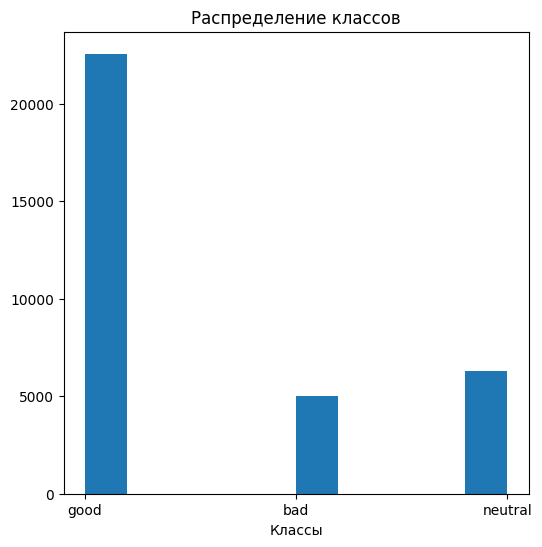

In [6]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))

plt.hist(data['review_type'].to_numpy())
plt.title('Распределение классов')
plt.xlabel("Классы")
plt.show()

In [7]:
SEED = 42
LABELS = ['good', 'bad', 'neutral']

required_columns = {'user_review', 'review_type'}
missing_columns = required_columns - set(data.columns)
if missing_columns:
    raise ValueError(f'Missing columns: {sorted(missing_columns)}')

unexpected_labels = set(data['review_type'].drop_nulls().unique()) - set(LABELS)
if unexpected_labels:
    raise ValueError(f'Unexpected labels: {sorted(unexpected_labels)}')

duplicate_rows = data.height - data.unique().height
data = data.filter(
    pl.col('user_review').is_not_null()
    & pl.col('review_type').is_not_null()
    & (pl.col('user_review').str.strip_chars() != '')
).unique(keep='first', maintain_order=True)

if 'film_name' in data.columns:
    film_names = data['film_name'].unique().to_list()
    if film_names == ['Unknown']:
        data = data.drop('film_name')

print(f'Data: {DATA_PATH}')
print(f'Exact duplicates removed: {duplicate_rows}')
print(f'Rows after cleaning: {data.height}')

## 3. Модель и токенизатор

`rubert-tiny2` — компактная русскоязычная BERT-модель. Слой классификации создаётся заново под три метки, поэтому предупреждение о новых весах классификатора ожидаемо.

In [8]:
from transformers import BertForSequenceClassification, AutoTokenizer

2025-04-21 21:54:00.658317: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1745272440.841605      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1745272440.894840      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [9]:
model_name = 'cointegrated/rubert-tiny2'

In [10]:
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = BertForSequenceClassification.from_pretrained(model_name, num_labels=3)

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/118M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at cointegrated/rubert-tiny2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


## 4. Токенизация и кодирование меток

Тексты усекаются по ограничению модели. При этом EDA показывает, что отзывы могут быть длинными: потерю концовки рецензии стоит учитывать при интерпретации качества.

In [11]:
data = data.with_columns(pl.col('user_review').map_elements(
lambda x: tokenizer(x, truncation=True), return_dtype=pl.Object).alias('tokenized_text'))

/tmp/ipykernel_19/50135890.py:1: MapWithoutReturnDtypeWarning: Calling `map_elements` without specifying `return_dtype` can lead to unpredictable results. Specify `return_dtype` to silence this warning.
  data = data.with_columns(pl.col('user_review').map_elements(


In [12]:
split_labels = data['review_type'].to_list()
label_map = dict(zip(LABELS, [0,1,2]))

data = data.with_columns(pl.col('review_type').replace(label_map).cast(pl.Int32))

In [13]:
train_data = data['review_type', 'tokenized_text']

In [14]:
model.config.label2id = {label: i for i, label in enumerate(LABELS)}
model.config.id2label = {i: label for i, label in enumerate(LABELS)}

In [15]:
import torch

In [16]:
from datasets import Dataset

In [17]:
from sklearn.model_selection import train_test_split
from transformers import BatchEncoding

In [18]:
token_data = train_data["tokenized_text"].to_list()


features = ["input_ids", "attention_mask", "token_type_ids"]
encodings = {feat: [d[feat] for d in token_data] for feat in features}
labels = train_data["review_type"].to_list() 

In [19]:
dataset_dict = {**encodings, "label": labels}

## 5. Train/test split

Индексы строк разбиваются тем же вызовом `sklearn.train_test_split`, что и в baseline, после той же очистки и с теми же параметрами. Поэтому обе модели обучаются и оцениваются на одинаковых текстах.

In [20]:
full_dataset = Dataset.from_dict(dataset_dict)
train_indices, test_indices = train_test_split(
    np.arange(data.height),
    test_size=0.2,
    random_state=SEED,
    stratify=split_labels,
)
dataset = {
    'train': full_dataset.select(train_indices),
    'test': full_dataset.select(test_indices),
}
for split_dataset in dataset.values():
    split_dataset.set_format('torch')
print(f'Train: {len(dataset["train"]):,}; test: {len(dataset["test"]):,}')

In [21]:
!pip install evaluate

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 kB 10.1 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.3.2
    Uninstalling fsspec-2025.3.2:
      Successfully uninstalled fsspec-2025.3.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2024.10.0 requires fsspec==2024.10.0, but you have fsspec 2024.12.0 which is incompatible.
torch 2.5.1+cu124 requires nvidia-cublas-cu12==12.4.5.8; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cublas-cu12 12.8.4.1 which is incompatible.
torch 2.5.1+cu124 requires nvidia-cudnn-cu12==9.1.0.70; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cudnn-cu12 9.3.0.75 which is incompatible.
torch 2.5.1+cu124 requires nvidia-cufft-cu12==

In [22]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
import evaluate
import wandb
from transformers import DataCollatorWithPadding
from collections import Counter

In [23]:
labels = dataset['train']['label'].tolist()

In [24]:
# Считаем количество каждого класса
label_counts = Counter(labels)
num_samples = len(labels)
num_classes = len(label_counts)

# Считаем веса классов: чем реже класс, тем выше его вес
CLASS_WEIGHTS = [num_samples / (num_classes * label_counts[i]) for i in range(num_classes)]
CLASS_WEIGHTS

[0.4995297892349394, 2.2608913370055084, 1.799163179916318]

In [25]:
from torch.nn import functional as F

## 6. Обучение

Обучаются классификатор и последний слой энкодера, остальные параметры заморожены. Веса классов компенсируют дисбаланс, а лучший чекпоинт выбирается по macro F1, чтобы редкие классы влияли на выбор модели.

In [26]:
wandb.init(mode='disabled')

f1_metric = evaluate.load('f1')
accuracy_metric = evaluate.load('accuracy')

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return {
        'accuracy': accuracy_metric.compute(predictions=predictions, references=labels)['accuracy'],
        'f1_macro': f1_metric.compute(predictions=predictions, references=labels, average='macro')['f1'],
        'f1_weighted': f1_metric.compute(predictions=predictions, references=labels, average='weighted')['f1'],
    }

class CustomTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")

        outputs = model(**inputs)
        logits = outputs.logits


        class_weights = torch.tensor(CLASS_WEIGHTS, device=logits.device, dtype=logits.dtype)
        loss = F.cross_entropy(logits, labels, weight=class_weights)

        return (loss, outputs) if return_outputs else loss

training_args = TrainingArguments(
    output_dir="/kaggle/working/my_model",
    learning_rate = 2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=10,
    weight_decay=0.1,
    eval_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model='f1_macro',
    greater_is_better=True,
    seed=SEED,
    data_seed=SEED,
    push_to_hub=False,
    report_to=None,
    logging_steps=100
)

base_model = 'cointegrated/rubert-tiny2'

tokenizer = AutoTokenizer.from_pretrained(base_model)
model = BertForSequenceClassification.from_pretrained(base_model, num_labels=len(LABELS))
model.config.label2id = {label: i for i, label in enumerate(LABELS)}
model.config.id2label = {i: label for i, label in enumerate(LABELS)}


for name, param in model.named_parameters():
    if 'classifier' in name or 'encoder.layer.1' in name:
        param.requires_grad = True
    else:
        param.requires_grad = False

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

trainer = CustomTrainer(
    model=model,
    args=training_args,
    train_dataset=dataset['train'],
    eval_dataset=dataset['test'],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

trainer.train()

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at cointegrated/rubert-tiny2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipykernel_19/1186854203.py:55: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `CustomTrainer.__init__`. Use `processing_class` instead.
  trainer = CustomTrainer(
wandb: WARNING The `run_name` is currently set to the same value as `TrainingArguments.output_dir`. If this was not intended, please specify a different run name by setting the `TrainingArguments.run_name` parameter.


Epoch,Training Loss,Validation Loss,F1
1,0.830900,0.767077,0.704796
2,0.759700,0.684451,0.745716
3,0.709300,0.661513,0.757628
4,0.664400,0.652410,0.751292
5,0.653300,0.636114,0.762821
6,0.652000,0.639722,0.754955
7,0.676600,0.632369,0.777889
8,0.637600,0.627570,0.770694
9,0.631700,0.631830,0.767256
10,0.686400,0.625868,0.771361


TrainOutput(global_step=16940, training_loss=0.702685421895249, metrics={'train_runtime': 4936.1356, 'train_samples_per_second': 54.881, 'train_steps_per_second': 3.432, 'total_flos': 4674105464560416.0, 'train_loss': 0.702685421895249, 'epoch': 10.0})

## 7. Оценка по классам

Ниже сохранён отчёт первого исторического запуска. Актуальная [версия 4 на Kaggle](https://www.kaggle.com/code/halssara/kinopoisk-bert) выполнена на том же разбиении, что и baseline: accuracy 0.7747, macro F1 0.6927, weighted F1 0.7807. F1 класса `neutral` составил 0.493. Матрица ошибок и тестовые предсказания сохранены в артефактах Kaggle.

In [27]:
import json
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

predictions = trainer.predict(dataset['test'])
preds = np.argmax(predictions.predictions, axis=-1)
true_labels = predictions.label_ids
report = classification_report(true_labels, preds, labels=range(len(LABELS)), target_names=LABELS, digits=3)
metrics = {
    'accuracy': accuracy_score(true_labels, preds),
    'f1_macro': f1_score(true_labels, preds, average='macro'),
    'f1_weighted': f1_score(true_labels, preds, average='weighted'),
}

OUTPUT_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
report_dict = classification_report(true_labels, preds, labels=range(len(LABELS)), target_names=LABELS, output_dict=True)
(OUTPUT_DIR / 'classification_report.json').write_text(json.dumps(report_dict, indent=2), encoding='utf-8')

test_texts = [data['user_review'][int(index)] for index in test_indices]
prediction_rows = pl.DataFrame({
    'text': test_texts,
    'true_label': [LABELS[int(index)] for index in true_labels],
    'predicted_label': [LABELS[int(index)] for index in preds],
})
prediction_rows.write_csv(OUTPUT_DIR / 'test_predictions.csv')

In [28]:
print(report)
print(json.dumps(metrics, indent=2))

matrix = confusion_matrix(true_labels, preds, labels=range(len(LABELS)), normalize='true')
display_matrix = ConfusionMatrixDisplay(matrix, display_labels=LABELS)
fig, ax = plt.subplots(figsize=(6, 5))
display_matrix.plot(ax=ax, cmap='Blues', values_format='.2f', colorbar=False)
ax.set_title('Normalized confusion matrix: RuBERT-tiny2')
plt.show()

misclassified = prediction_rows.filter(
    pl.col('true_label') != pl.col('predicted_label')
).with_columns(
    pl.col('text').str.slice(0, 500).alias('text_excerpt')
).select(['true_label', 'predicted_label', 'text_excerpt']).head(5)
misclassified

              precision    recall  f1-score   support

        good       0.93      0.81      0.86      4495
         bad       0.65      0.79      0.72      1013
     neutral       0.44      0.57      0.49      1265

    accuracy                           0.76      6773
   macro avg       0.67      0.72      0.69      6773
weighted avg       0.79      0.76      0.77      6773



## 8. Сохранение модели

Сохраняются веса и конфигурация лучшего чекпоинта, токенизатор, метрики и тестовые предсказания. Ниже приведены примеры inference после обучения.

In [29]:
model_output_dir = OUTPUT_DIR / 'final_model'
trainer.save_model(str(model_output_dir))
tokenizer.save_pretrained(str(model_output_dir))

In [ ]:
def predict_sentiment(text):
    inputs = tokenizer(
        text,
        return_tensors='pt',
        truncation=True,
        max_length=tokenizer.model_max_length,
    )
    inputs = {name: tensor.to(model.device) for name, tensor in inputs.items()}

    model.eval()
    with torch.no_grad():
        logits = model(**inputs).logits
        probabilities = torch.softmax(logits, dim=-1)[0].cpu().numpy()

    prediction_index = int(probabilities.argmax())
    return {
        'label': model.config.id2label[prediction_index],
        'confidence': float(probabilities[prediction_index]),
        'probabilities': {
            model.config.id2label[index]: float(probability)
            for index, probability in enumerate(probabilities)
        },
    }


examples = [
    'Фильм очень понравился: отличная игра актёров и сильная режиссура!',
    'Ужасное кино: скучно, нелогично, актёры совершенно не убедительны.',
    'Средний фильм: есть как удачные сцены, так и заметные недостатки.',
]
for example in examples:
    print(example)
    print(predict_sentiment(example))
    print()

## Ограничения и следующие шаги

- Названия фильмов в исходном датасете отсутствуют, поэтому нельзя исключить попадание отзывов одного фильма в train и test.
- Длинные тексты усекаются; часть контекста может теряться.
- Метки отражают категории источника и могут содержать субъективную неоднозначность, особенно для `neutral`.
- Разбиение синхронизировано с baseline; актуальные метрики, матрица ошибок и примеры неверных предсказаний сохранены в версии 4 на Kaggle.